In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plt.style.use('seaborn-v0_8-whitegrid')

def classification_metrics(model, X_test, y_test):
    pred = model.predict(X_test)
    if hasattr(model, "decision_function"):
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, scores)
    }

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plt.style.use('seaborn-v0_8-whitegrid')

def classification_metrics(model, X_test, y_test):
    pred = model.predict(X_test)
    if hasattr(model, "decision_function"):
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, scores)
    }

In [7]:
# Cell 2: Data Loading & Split
try:
    df = pd.read_excel("Book1.xlsx")
    df.columns = [c.replace('x.', '') for c in df.columns]
    yb = (df["y"] == "M").astype(int)
    Xb = df.drop(
        columns=["Unnamed: 0", "y"] if "Unnamed: 0" in df.columns else ["y"]
    )
    print("Successfully loaded Book1.xlsx!")
except Exception as e:
    print("Book1.xlsx not found, loading directly from scikit-learn...")
    from sklearn.datasets import load_breast_cancer

    data = load_breast_cancer(as_frame=True)
    Xb, yb = data.data, data.target

# Train/Test Split (80/20 Stratified)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.20, stratify=yb, random_state=RANDOM_STATE
)

print("Class distribution:\n", yb.value_counts())
print("Predictor count:", Xb.shape[1])
print("Xb_train shape:", Xb_train.shape)

Book1.xlsx not found, loading directly from scikit-learn...
Class distribution:
 target
1    357
0    212
Name: count, dtype: int64
Predictor count: 30
Xb_train shape: (455, 30)


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

# Global Parameters
RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plt.style.use('seaborn-v0_8-whitegrid')

def classification_metrics(model, X_test, y_test):
    """Computes standard evaluation metrics for classification models."""
    pred = model.predict(X_test)
    if hasattr(model, "decision_function"):
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, scores)
    }

In [10]:
# Load Wisconsin Breast Cancer Dataset
try:
    df = pd.read_excel("Book1.xlsx")
    df.columns = [c.replace('x.', '') for c in df.columns]
    yb = (df["y"] == "M").astype(int)
    Xb = df.drop(columns=["Unnamed: 0", "y"] if "Unnamed: 0" in df.columns else ["y"])
    print("Successfully loaded dataset from Book1.xlsx!")
except Exception as e:
    print("Book1.xlsx not found locally. Loading directly from scikit-learn...")
    from sklearn.datasets import load_breast_cancer
    data = load_breast_cancer(as_frame=True)
    Xb, yb = data.data, data.target

# Train/Test Split (80/20 Stratified)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.20, stratify=yb, random_state=RANDOM_STATE
)

print("\nClass distribution:")
print(yb.value_counts())
print("\nPredictor count:", Xb.shape[1])
print("Training set shape:", Xb_train.shape)

Book1.xlsx not found locally. Loading directly from scikit-learn...

Class distribution:
target
1    357
0    212
Name: count, dtype: int64

Predictor count: 30
Training set shape: (455, 30)


In [11]:
# Create Pipeline with StandardScaler (Crucial for SVM distance margins)
pipe_svm = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(random_state=RANDOM_STATE))
])

# Define Grid Search across Linear, RBF, and Polynomial Kernels
param_grid_svm = [
    {
        "model__kernel": ["linear"],
        "model__C": np.logspace(-2, 3, 6)
    },
    {
        "model__kernel": ["rbf"],
        "model__C": np.logspace(-2, 3, 6),
        "model__gamma": ["scale", "auto", 0.01, 0.1, 1.0]
    },
    {
        "model__kernel": ["poly"],
        "model__degree": [2, 3],
        "model__C": np.logspace(-2, 2, 5)
    }
]

grid_svm = GridSearchCV(
    pipe_svm,
    param_grid=param_grid_svm,
    scoring="roc_auc",
    cv=CV,
    n_jobs=-1
)
grid_svm.fit(Xb_train, yb_train)

print("Best Kernel & Parameters:", grid_svm.best_params_)
print("Best 5-Fold Cross-Validated ROC-AUC:", round(grid_svm.best_score_, 4))

metrics_svm = classification_metrics(grid_svm.best_estimator_, Xb_test, yb_test)
pd.DataFrame([metrics_svm], index=["Tuned SVM Model"])

Best Kernel & Parameters: {'model__C': np.float64(10.0), 'model__gamma': 0.01, 'model__kernel': 'rbf'}
Best 5-Fold Cross-Validated ROC-AUC: 0.9964


,Accuracy,Precision,Recall,F1,ROC_AUC
Tuned SVM Model,0.982456,0.986111,0.986111,0.986111,0.997685


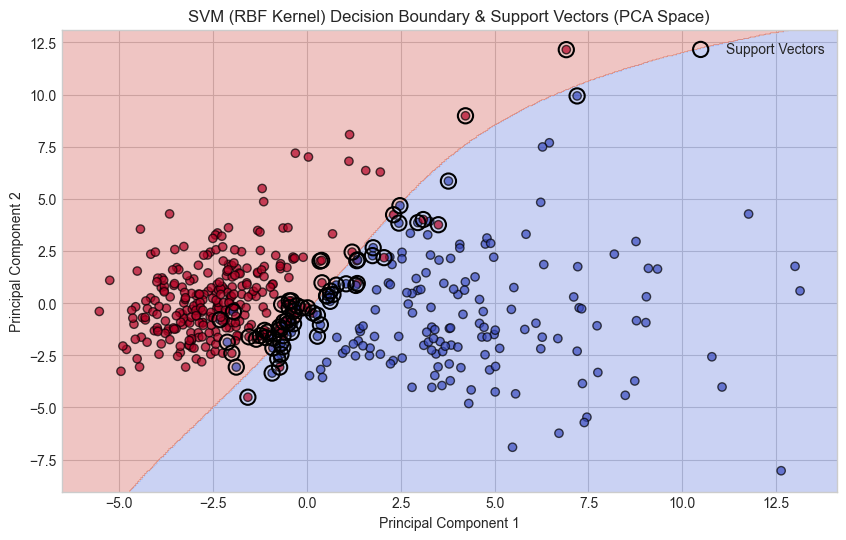

In [12]:
# Project predictors to 2D using PCA for visual evaluation
pca = PCA(n_components=2)
scaler = StandardScaler()

Xb_train_scaled = scaler.fit_transform(Xb_train)
Xb_train_pca = pca.fit_transform(Xb_train_scaled)

# Train 2D SVM model for boundary visualization
svm_2d = SVC(
    kernel=grid_svm.best_params_['model__kernel'],
    C=grid_svm.best_params_.get('model__C', 1.0),
    gamma=grid_svm.best_params_.get('model__gamma', 'scale'),
    random_state=RANDOM_STATE
)
svm_2d.fit(Xb_train_pca, yb_train)

# Mesh grid calculation
x_min, x_max = Xb_train_pca[:, 0].min() - 1, Xb_train_pca[:, 0].max() + 1
y_min, y_max = Xb_train_pca[:, 1].min() - 1, Xb_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))

Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(Xb_train_pca[:, 0], Xb_train_pca[:, 1], c=yb_train, cmap="coolwarm", edgecolors="k", alpha=0.7)

# Highlight Support Vectors
sv = svm_2d.support_vectors_
plt.scatter(sv[:, 0], sv[:, 1], s=120, facecolors="none", edgecolors="black", linewidths=1.5, label="Support Vectors")

plt.title(f"SVM ({grid_svm.best_params_['model__kernel'].upper()} Kernel) Decision Boundary & Support Vectors (PCA Space)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

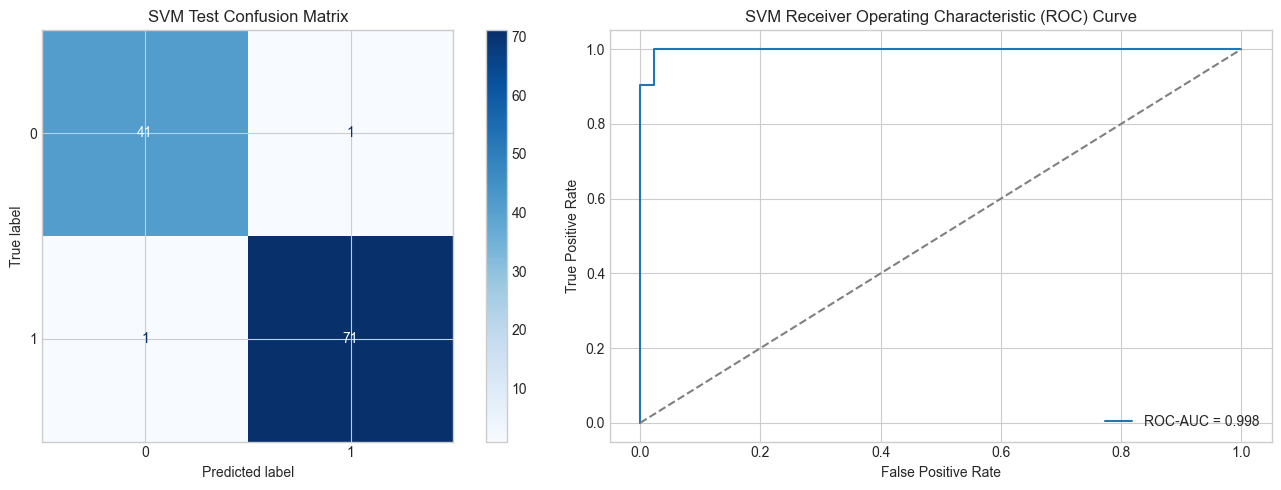

In [13]:
# Best estimator test predictions
best_model = grid_svm.best_estimator_
pred_b = best_model.predict(Xb_test)
scores_b = best_model.decision_function(Xb_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(yb_test, pred_b, ax=axes[0], cmap="Blues")
axes[0].set_title("SVM Test Confusion Matrix")

# ROC Curve
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(yb_test, scores_b)
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {metrics_svm['ROC_AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("SVM Receiver Operating Characteristic (ROC) Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

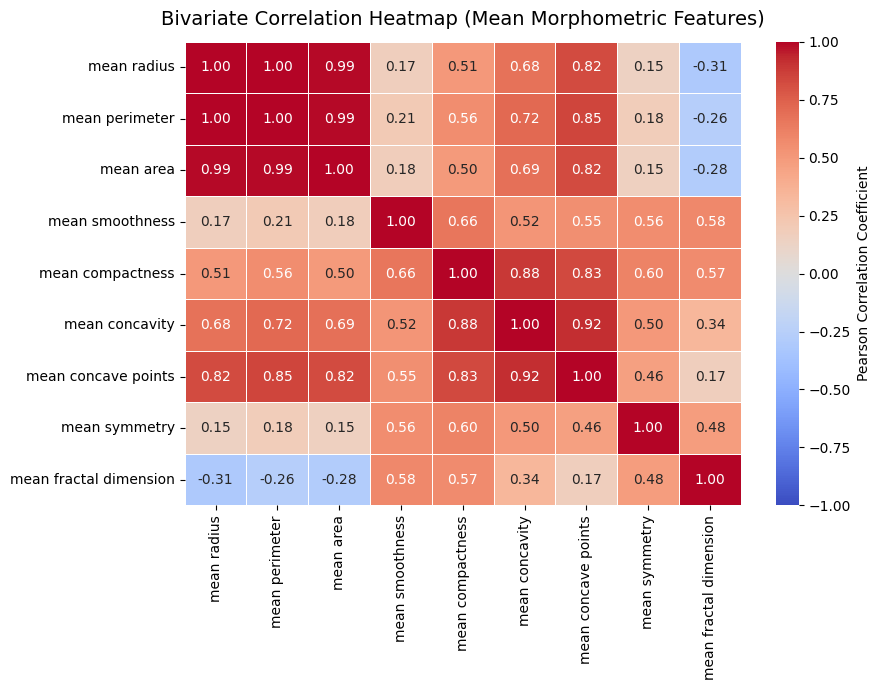

Saved successfully as 'correlation_heatmap.png'


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

# 1. Load Dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)

# 2. Select key mean morphometric features to demonstrate collinearity
mean_features = [
    'mean radius', 'mean perimeter', 'mean area', 
    'mean smoothness', 'mean compactness', 'mean concavity', 
    'mean concave points', 'mean symmetry', 'mean fractal dimension'
]
corr_matrix = df[mean_features].corr()

# 3. Plot Correlation Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

plt.title("Bivariate Correlation Heatmap (Mean Morphometric Features)", fontsize=14, pad=12)
plt.tight_layout()

# 4. Save Figure for Word Document Insertion
plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved successfully as 'correlation_heatmap.png'")